Training images: 8,225
Images with annotations: 8,225
Total annotated objects: 14,140


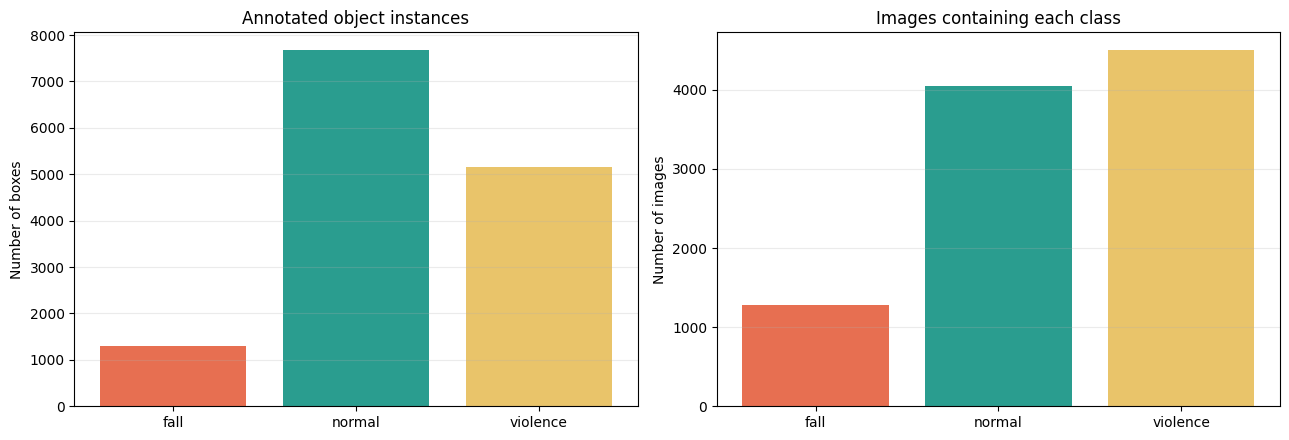

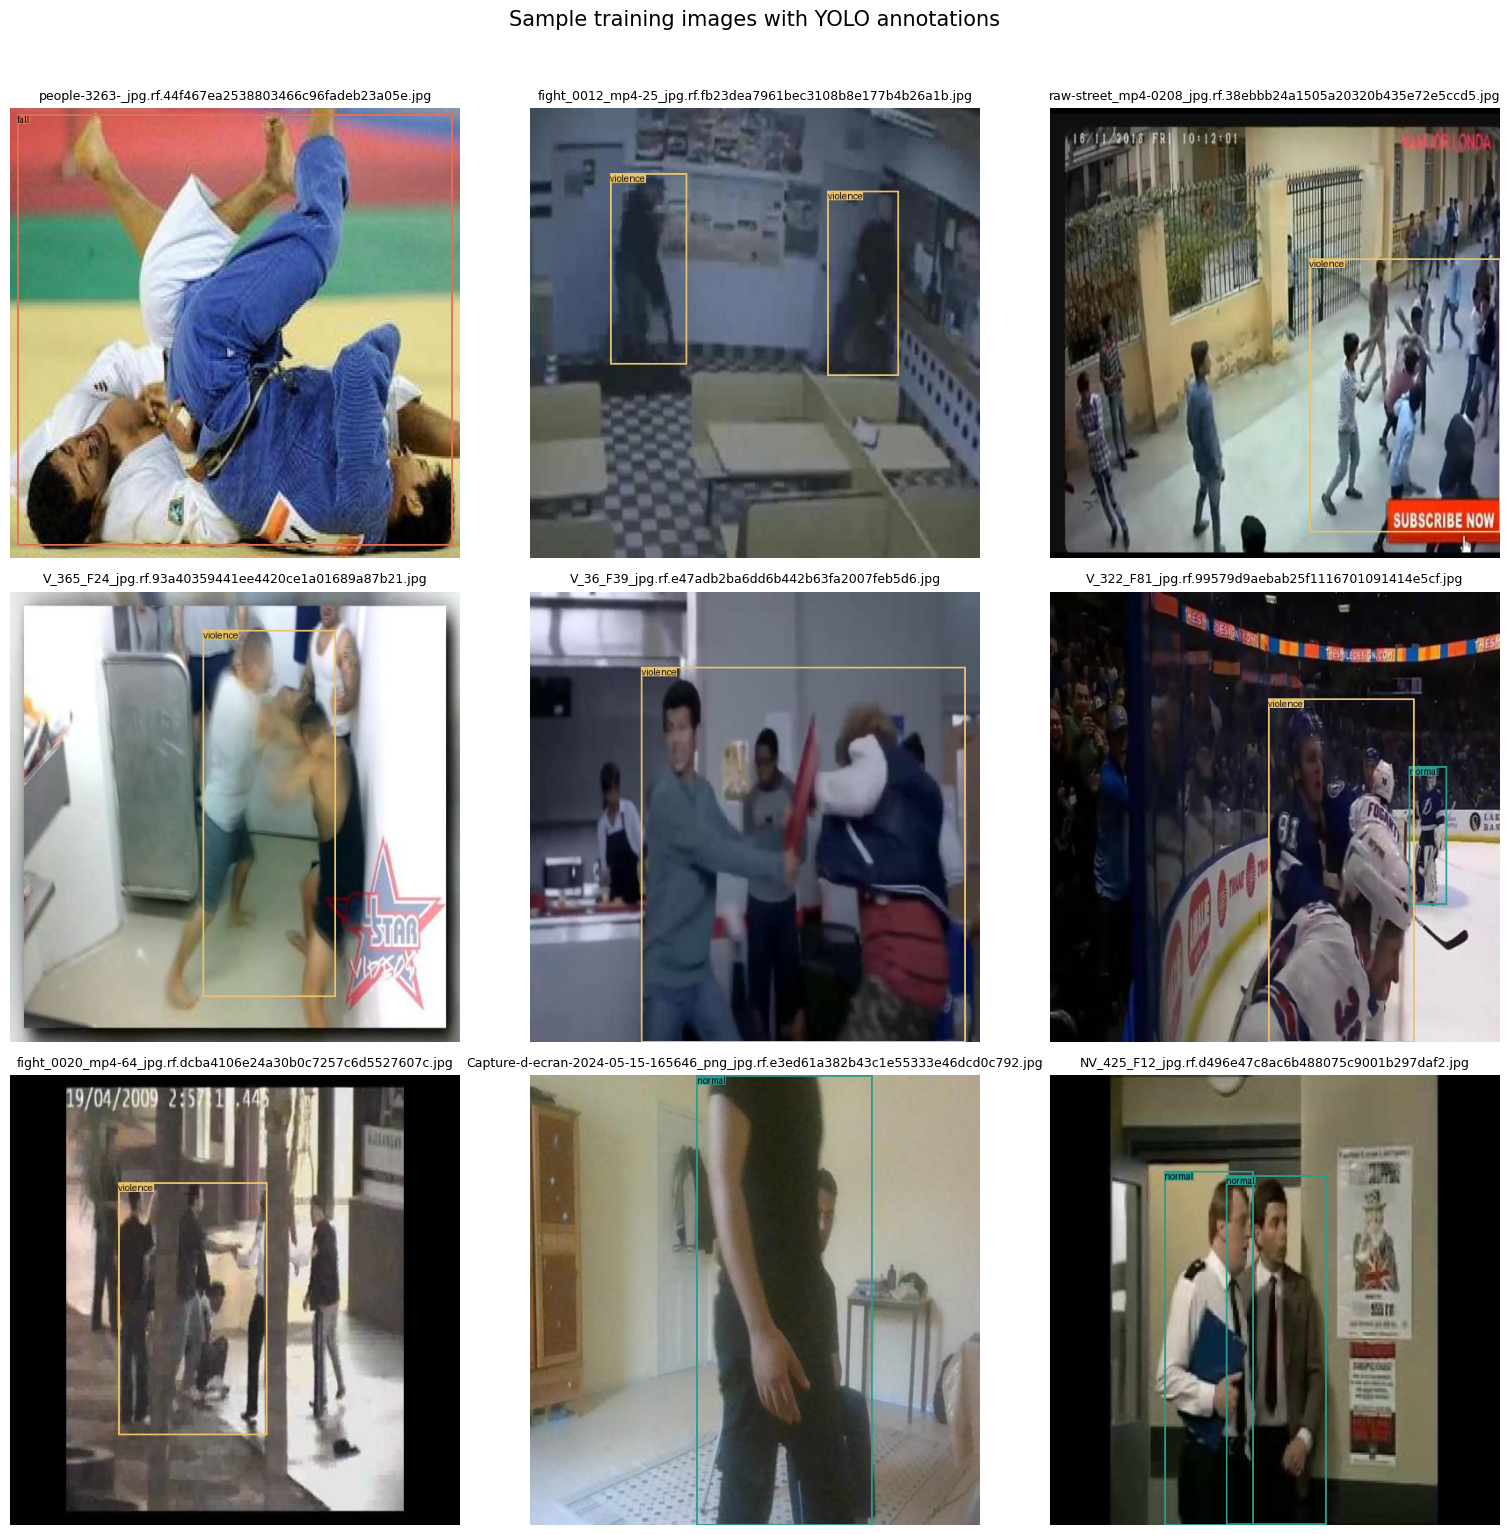

In [ ]:
from pathlib import Path
from collections import Counter
import random

import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

DATASET_DIR = Path("/kaggle/input/datasets/phnguyencs/violence/data")
TRAIN_IMAGES_DIR = DATASET_DIR / "train" / "images"
TRAIN_LABELS_DIR = DATASET_DIR / "train" / "labels"
CLASS_NAMES = ["fall", "normal", "violence"]
COLORS = {"fall": "#e76f51", "normal": "#2a9d8f", "violence": "#e9c46a"}


IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}
image_paths = sorted(
    path for path in TRAIN_IMAGES_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
)

labels_by_image = {}
instance_counts = Counter()
image_counts = Counter()

for image_path in image_paths:
    label_path = TRAIN_LABELS_DIR / f"{image_path.stem}.txt"
    image_labels = []

    if label_path.exists():
        for line_number, line in enumerate(label_path.read_text().splitlines(), start=1):
            values = line.split()
            class_id = int(values[0])
            box = tuple(float(value) for value in values[1:])
            image_labels.append((class_id, box))
            instance_counts[class_id] += 1

    labels_by_image[image_path] = image_labels
    image_counts.update({class_id for class_id, _ in image_labels})

print(f"Training images: {len(image_paths):,}")
print(f"Images with annotations: {len(labels_by_image):,}")
print(f"Total annotated objects: {sum(instance_counts.values()):,}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
class_labels = CLASS_NAMES
bar_colors = [COLORS[name] for name in class_labels]

axes[0].bar(
    class_labels,
    [instance_counts[class_id] for class_id in range(len(CLASS_NAMES))],
    color=bar_colors,
)
axes[0].set_title("Annotated object instances")
axes[0].set_ylabel("Number of boxes")
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(
    class_labels,
    [image_counts[class_id] for class_id in range(len(CLASS_NAMES))],
    color=bar_colors,
)
axes[1].set_title("Images containing each class")
axes[1].set_ylabel("Number of images")
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


def draw_yolo_annotations(image_path, image_labels):
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    image_width, image_height = image.size

    for class_id, (x_center, y_center, box_width, box_height) in image_labels:
        left = (x_center - box_width / 2) * image_width
        top = (y_center - box_height / 2) * image_height
        right = (x_center + box_width / 2) * image_width
        bottom = (y_center + box_height / 2) * image_height
        class_name = CLASS_NAMES[class_id]
        color = COLORS[class_name]

        draw.rectangle((left, top, right, bottom), outline=color, width=max(2, image_width // 250))
        text = class_name
        text_box = draw.textbbox((left, top), text)
        draw.rectangle(text_box, fill=color)
        draw.text((left, top), text, fill="black")

    return image

rng = random.Random()
annotated_images = [path for path in image_paths if labels_by_image[path]]
sample_size = 9
sample_paths = rng.sample(annotated_images, sample_size)

columns = 3
rows = (sample_size + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(16, 5 * rows))
axes = list(axes.flat) 

for axis, image_path in zip(axes, sample_paths):
    axis.imshow(draw_yolo_annotations(image_path, labels_by_image[image_path]))
    axis.set_title(image_path.name, fontsize=9)
    axis.axis("off")

for axis in axes[sample_size:]:
    axis.axis("off")

plt.suptitle("Sample training images with YOLO annotations", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()


In [7]:
from ultralytics import YOLO

DATA_CONFIG = str(DATASET_DIR / "data.yaml")
MODEL_NAME = "yolo26m.pt"

model = YOLO(MODEL_NAME)
training_results = model.train(
    data=DATA_CONFIG,
    split="test",
    epochs=50,
    imgsz=640,
    batch=32,          
    device=[0,1],          
    workers=8,
    patience=10,
    project="runs/train",
    name="yolo26s-violence",
    exist_ok=True,
    pretrained=True,
    seed=42,

    flipud=0.0,              # vertical flip
    fliplr=0.5,              # horizontal flip
    degrees=5.0,             
    shear=0.0,             
    perspective=0.0,         

    
    mosaic=0.5,             
    close_mosaic=10,         
    mixup=0.0,               
    scale=0.5,               
    translate=0.1,           

    
    hsv_h=0.015,             # Hue 
    hsv_s=0.5,               # Saturation 
    hsv_v=0.4,               # Brightness 
    erasing=0.2,             
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Ultralytics 8.4.143 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/phnguyencs/violence/data/data.yaml, degrees=5.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropou

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/50      9.01G      1.752      2.503    0.03446          1        640: 100% ━━━━━━━━━━━━ 258/258 1.7it/s 2:280.4ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 65/65 2.0it/s 33.0s0.5ss
                   all       4154       5672      0.384      0.437      0.359      0.154

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/50      9.07G      1.761       2.35    0.03472          3        640: 100% ━━━━━━━━━━━━ 258/258 1.8it/s 2:270.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 65/65 1.9it/s 33.7s0.5ss
                   all       4154       5672      0.473      0.386      0.361      0.153

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/50      9.07G      1.751      2.276    0.03369          1       

In [8]:
image_paths = sorted(list((DATASET_DIR / "valid/images").glob("*.jpg")))[:10]
image_paths

[PosixPath('/kaggle/input/datasets/phnguyencs/violence/data/valid/images/00002_png_jpg.rf.7a72ab7a9ef22b97fc51528eb6b1f9d0.jpg'),
 PosixPath('/kaggle/input/datasets/phnguyencs/violence/data/valid/images/00004_png_jpg.rf.564c0fcd38cd2808ca8129175492c48d.jpg'),
 PosixPath('/kaggle/input/datasets/phnguyencs/violence/data/valid/images/00005_png_jpg.rf.1804ca9f4caa4da3a0c5a4fbd3830eb7.jpg'),
 PosixPath('/kaggle/input/datasets/phnguyencs/violence/data/valid/images/00009_png_jpg.rf.4e0c09c03e365f6f5fb6eb7fbd147ec1.jpg'),
 PosixPath('/kaggle/input/datasets/phnguyencs/violence/data/valid/images/00009_png_jpg.rf.d198a38e5070129dd5a21e894b1dcae6.jpg'),
 PosixPath('/kaggle/input/datasets/phnguyencs/violence/data/valid/images/00010_png_jpg.rf.33c6e3cf156ba5a818c175d1151ff088.jpg'),
 PosixPath('/kaggle/input/datasets/phnguyencs/violence/data/valid/images/00014_png_jpg.rf.16f10ae6ca621ca269bae4af555c7517.jpg'),
 PosixPath('/kaggle/input/datasets/phnguyencs/violence/data/valid/images/00015_png_jpg.rf.

In [26]:
# Visualize predictions on a few validation images.
best_model = YOLO("/kaggle/working/runs/detect/runs/train/yolo26s-violence/weights/best.pt")
best_model.predict(
    source=image_paths,
    imgsz=640,
    conf=0.8,
    device=0,
    save=True,
    project="runs/predict",
    name="yolo26s-violence-valid",
    exist_ok=True,
    max_det=100,
)


0: 640x640 1 normal, 21.6ms
1: 640x640 1 normal, 21.6ms
2: 640x640 1 normal, 21.6ms
3: 640x640 1 normal, 21.6ms
4: 640x640 1 normal, 21.6ms
5: 640x640 1 normal, 21.6ms
6: 640x640 1 normal, 21.6ms
7: 640x640 1 normal, 21.6ms
8: 640x640 1 normal, 21.6ms
9: 640x640 1 normal, 21.6ms
Speed: 3.8ms preprocess, 21.6ms inference, 3.0ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /kaggle/working/runs/detect/runs/train/yolo26s-violence/weights/runs/detect/runs/predict/yolo26s-violence-valid


[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: 'fall', 1: 'normal', 2: 'violence'}
 obb: None
 orig_img: array([[[245, 236, 233],
         [240, 231, 227],
         [235, 227, 220],
         ...,
         [146, 161, 207],
         [151, 165, 213],
         [148, 162, 210]],
 
        [[245, 236, 233],
         [240, 231, 227],
         [235, 227, 220],
         ...,
         [145, 160, 206],
         [150, 164, 212],
         [150, 164, 212]],
 
        [[245, 236, 233],
         [240, 231, 227],
         [235, 227, 220],
         ...,
         [144, 159, 205],
         [149, 163, 211],
         [154, 168, 216]],
 
        ...,
 
        [[ 84, 125,  98],
         [ 81, 122,  95],
         [ 94, 135, 108],
         ...,
         [190, 189, 193],
         [156, 155, 159],
         [158, 157, 161]],
 
        [[ 85, 126,  99],
         [ 84, 125,  98],
         [ 98, 139,